In [1]:
from pathlib import Path

import pandas as pd
import yaml


def find_repo_root(start: Path) -> Path:
    """Walk up from `start` until the folder containing pyproject.toml is found."""
    for folder in [start, *start.parents]:
        if (folder / "pyproject.toml").exists():
            return folder
    raise FileNotFoundError("pyproject.toml not found - are you inside the repo?")


ROOT = find_repo_root(Path.cwd())
config = yaml.safe_load((ROOT / "configs" / "config.yaml").read_text())

df = pd.read_csv(ROOT / config["datasets"]["ai4i"])
print(f"Repo root: {ROOT}")
print(f"Shape: {df.shape[0]} rows x {df.shape[1]} columns")

Repo root: /home/danee/projects/failsense
Shape: 10000 rows x 14 columns


## 1. Data quality: types, missing values, duplicates

In [2]:
df.head()

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


In [3]:
quality = pd.DataFrame(
    {
        "dtype": df.dtypes.astype(str),
        "missing": df.isna().sum(),
        "unique": df.nunique(),
    }
)
quality

,dtype,missing,unique
UDI,int64,0,10000
Product ID,str,0,10000
Type,str,0,3
Air temperature [K],float64,0,93
Process temperature [K],float64,0,82
Rotational speed [rpm],int64,0,941
Torque [Nm],float64,0,577
Tool wear [min],int64,0,246
Machine failure,int64,0,2
TWF,int64,0,2


In [4]:
print(f"Duplicate rows:          {df.duplicated().sum()}")
print(f"Duplicate UDI:           {df['UDI'].duplicated().sum()}")
print(f"Duplicate Product ID:    {df['Product ID'].duplicated().sum()}")

Duplicate rows:          0
Duplicate UDI:           0
Duplicate Product ID:    0


**Findings – data quality**
- 10,000 rows, 14 columns, no missing values, no duplicate rows (synthetic data).
- `UDI` and `Product ID` are unique identifiers → drop, never use as features.
  `Product ID` also starts with the `Type` letter (redundant).
- `Type` (L/M/H) is categorical → needs encoding (OneHotEncoder).
- `Machine failure` is the binary target.
- `TWF`, `HDF`, `PWF`, `OSF`, `RNF` are failure modes → **leakage risk**, must never be features.
- `Air temperature` has only 93 distinct values → rounded to 0.1 K.

## 2. Target: failure rate and failure modes

In [5]:
target = df["Machine failure"]
counts = target.value_counts().sort_index()
rate = target.mean()

print(counts.to_string())
print(f"\nFailure rate: {rate:.2%}")
print(f"Accuracy of a model that ALWAYS predicts 'no failure': {1 - rate:.2%}")

Machine failure
0    9661
1     339

Failure rate: 3.39%
Accuracy of a model that ALWAYS predicts 'no failure': 96.61%


In [6]:
FAILURE_MODES = ["TWF", "HDF", "PWF", "OSF", "RNF"]

print("Count per failure mode:")
print(df[FAILURE_MODES].sum().to_string())

any_mode = df[FAILURE_MODES].any(axis=1)
print(f"\nFailure = 1 but NO mode flagged:  {((target == 1) & ~any_mode).sum()}")
print(f"Mode flagged but failure = 0:      {((target == 0) & any_mode).sum()}")
print(f"Rows with more than one mode:      {(df[FAILURE_MODES].sum(axis=1) > 1).sum()}")

Count per failure mode:
TWF     46
HDF    115
PWF     95
OSF     98
RNF     19

Failure = 1 but NO mode flagged:  9
Mode flagged but failure = 0:      18
Rows with more than one mode:      24


In [7]:
mode_but_no_failure = (target == 0) & any_mode
print("Modes in the 18 rows with failure = 0:")
print(df.loc[mode_but_no_failure, FAILURE_MODES].sum().to_string())

Modes in the 18 rows with failure = 0:
TWF     0
HDF     0
PWF     0
OSF     0
RNF    18


**Findings – target**
- 339 failures out of 10,000 → **failure rate 3.39 %** (strongly imbalanced).
- A model that always predicts "no failure" reaches **96.61 % accuracy** but catches **0** failures
  → accuracy is useless here; use **PR-AUC** and **Recall** (DummyClassifier as baseline).
- Failure modes overlap: 373 mode flags for 339 failures, 24 rows have more than one mode
  → failure-mode prediction is closer to **multi-label** than multi-class.
- **Inconsistencies (27 rows):**
  - 9 rows: `Machine failure = 1` but no mode flagged.
  - 18 rows: `RNF = 1` but `Machine failure = 0` (18 of 19 RNF rows).
- Decision: keep `Machine failure` as the target **as recorded**, do not edit labels by hand.
  Document in the Model Card. RNF is random by design and not predictable.

## 3. Sensor distributions: failure vs. no failure

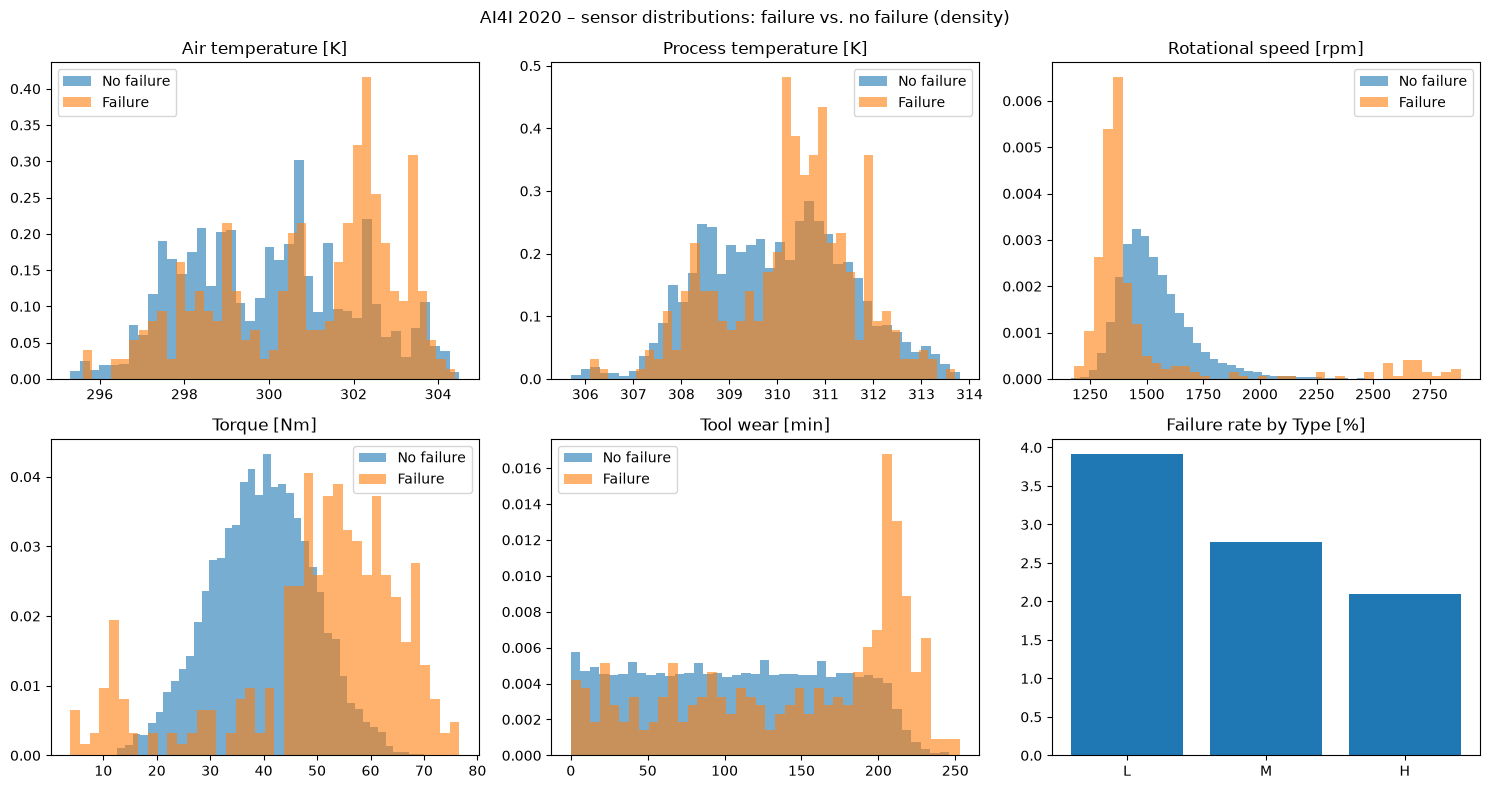

In [8]:
import matplotlib.pyplot as plt

SENSORS = [
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]",
]

fig, axes = plt.subplots(2, 3, figsize=(15, 8))

for ax, col in zip(axes.flat, SENSORS, strict=False):
    ax.hist(df.loc[target == 0, col], bins=40, density=True, alpha=0.6, label="No failure")
    ax.hist(df.loc[target == 1, col], bins=40, density=True, alpha=0.6, label="Failure")
    ax.set_title(col)
    ax.legend()

rate_by_type = df.groupby("Type")["Machine failure"].mean().reindex(["L", "M", "H"])
axes.flat[5].bar(rate_by_type.index, rate_by_type.values * 100)
axes.flat[5].set_title("Failure rate by Type [%]")

fig.suptitle("AI4I 2020 – sensor distributions: failure vs. no failure (density)")
fig.tight_layout()

fig_dir = ROOT / config["paths"]["reports"] / "figures"
fig_dir.mkdir(parents=True, exist_ok=True)
fig.savefig(fig_dir / "01_eda_distributions.png", dpi=120)
plt.show()

In [9]:
df[SENSORS + ["Machine failure"]].groupby("Machine failure").median().T.round(1)

Machine failure,0,1
Air temperature [K],300.0,301.6
Process temperature [K],310.0,310.4
Rotational speed [rpm],1507.0,1365.0
Torque [Nm],39.9,53.7
Tool wear [min],107.0,165.0


**Findings – distributions**
- **Torque** (median 39.9 → 53.7 Nm) and **rotational speed** (1507 → 1365 rpm) separate failures best.
- Failures appear at **both extremes**: high torque/low speed and very low torque/very high speed
  → non-linear pattern (power failure). A linear model will miss one side;
  tree models or the engineered feature **power = torque × speed × 2π/60** should handle it.
- **Tool wear**: failures jump at ~200–240 min (tool wear failure). Combined with high torque
  → overstrain → engineered feature **strain = tool wear × torque**.
- **Type**: failure rate L ≈ 3.9 % > M ≈ 2.8 % > H ≈ 2.1 % → useful categorical feature.
- Air temperature alone is weak; test **temperature difference = process − air** (heat dissipation).
- Next: engineer the three physical features (30.10) and compare models with/without them.

## 2. Failure mechanisms, correlations and leakage

Cell A — Setup and physical features (for exploration only):

In [10]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

FIG_DIR = Path("../reports/figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)

AIR = "Air temperature [K]"
PROC = "Process temperature [K]"
SPEED = "Rotational speed [rpm]"
TORQUE = "Torque [Nm]"
WEAR = "Tool wear [min]"
TARGET = "Machine failure"
MODES = ["TWF", "HDF", "PWF", "OSF", "RNF"]

# Work on a copy: these features are for exploration only.
# The production versions will live in src/failsense/features/ (30.10).
eda = df.copy()
eda["temp_diff_K"] = eda[PROC] - eda[AIR]
eda["power_W"] = eda[TORQUE] * eda[SPEED] * 2 * np.pi / 60
eda["strain_minNm"] = eda[WEAR] * eda[TORQUE]
eda[["temp_diff_K", "power_W", "strain_minNm"]].describe().round(1)

,temp_diff_K,power_W,strain_minNm
count,10000.0,10000.0,10000.0
mean,10.0,6279.7,4314.7
std,1.0,1067.4,2826.6
min,7.6,1148.4,0.0
25%,9.3,5561.2,1963.6
50%,9.8,6271.0,4013.0
75%,11.0,7003.0,6279.0
max,12.1,10469.9,16497.0


Cell B — Failure modes: counts and rate per product type:

In [11]:
display(eda[MODES].sum().rename("rows_flagged").to_frame())
display((eda.groupby("Type")[MODES].mean() * 100).round(2).add_suffix(" %"))

,rows_flagged
TWF,46
HDF,115
PWF,95
OSF,98
RNF,19


,TWF %,HDF %,PWF %,OSF %,RNF %
Type,,,,,
H,0.70,0.80,0.50,0.20,0.40
L,0.42,1.27,0.98,1.45,0.22
M,0.47,1.03,1.03,0.30,0.07


Cell C — Median sensor values: healthy vs. each failure mode:

In [12]:
cols = [AIR, PROC, SPEED, TORQUE, WEAR, "temp_diff_K", "power_W", "strain_minNm"]
healthy_mask = eda[TARGET].eq(0) & eda[MODES].sum(axis=1).eq(0)

summary = pd.concat(
    [eda.loc[healthy_mask, cols].median().rename("healthy")]
    + [eda.loc[eda[m].eq(1), cols].median().rename(m) for m in MODES],
    axis=1,
)
summary.round(1)

,healthy,TWF,HDF,PWF,OSF,RNF
Air temperature [K],300.0,300.4,302.5,300.4,300.0,300.8
Process temperature [K],310.0,310.2,310.7,310.2,310.1,311.0
Rotational speed [rpm],1507.0,1516.0,1346.0,1386.0,1360.5,1481.0
Torque [Nm],39.8,37.8,52.6,63.6,57.7,45.7
Tool wear [min],107.0,214.5,106.0,100.0,207.0,144.0
temp_diff_K,9.8,9.6,8.3,9.7,10.0,9.6
power_W,6243.0,6021.2,7343.5,9100.4,8175.3,6826.9
strain_minNm,3951.2,7982.8,5580.0,3608.8,11689.4,6124.8


Cell D — Rediscover the failure rules visually:

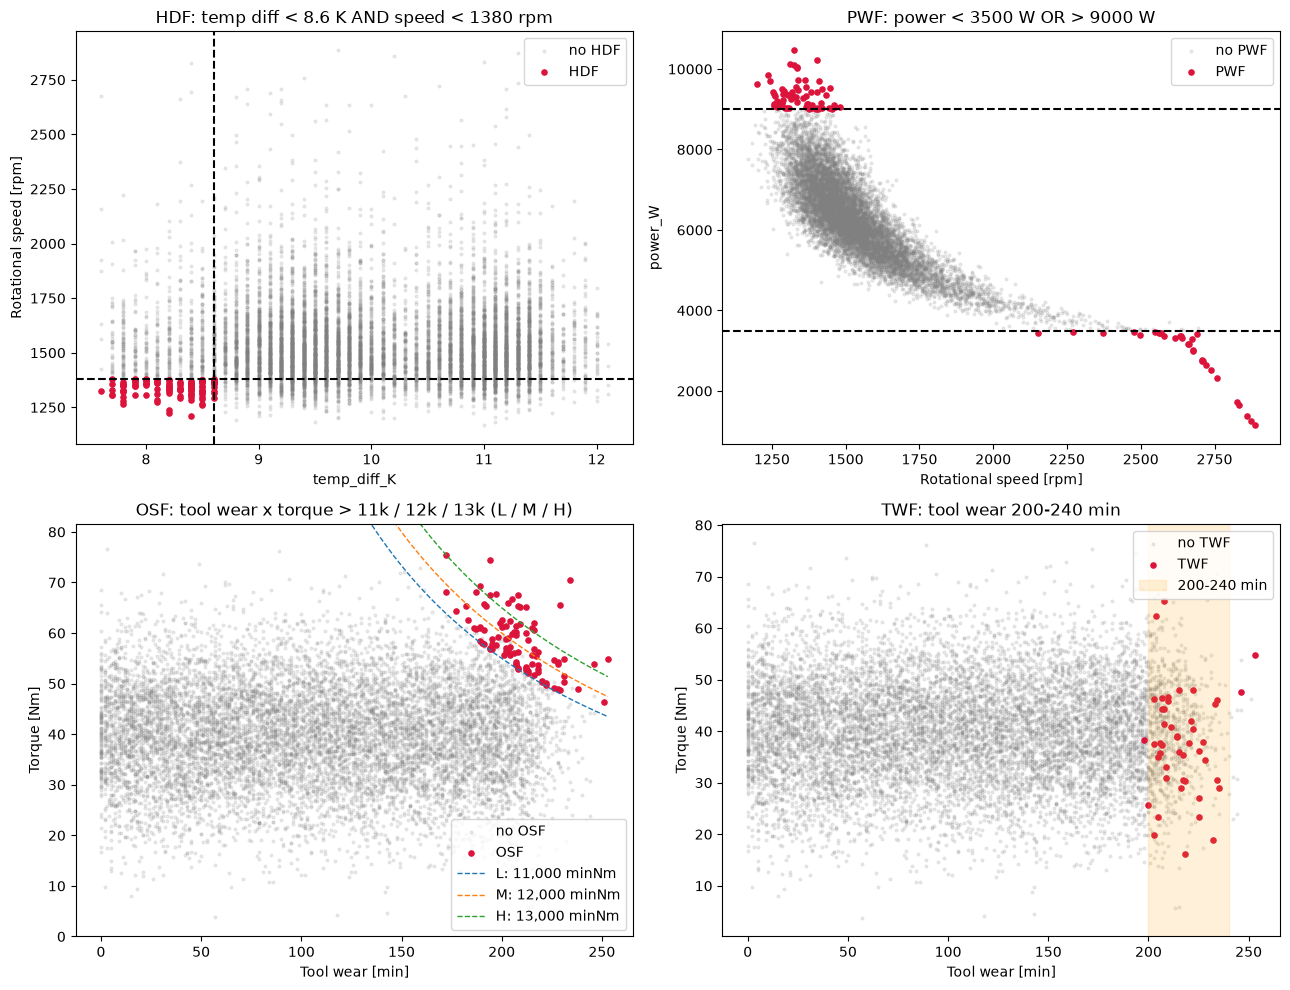

In [13]:
def mode_scatter(ax, x, y, mode, title):
    """Grey = rows without this mode, red = rows with this mode."""
    off = eda[mode].eq(0)
    ax.scatter(eda.loc[off, x], eda.loc[off, y], s=4, alpha=0.15, color="grey", label=f"no {mode}")
    ax.scatter(eda.loc[~off, x], eda.loc[~off, y], s=14, color="crimson", label=mode)
    ax.set(xlabel=x, ylabel=y, title=title)


fig, axes = plt.subplots(2, 2, figsize=(13, 10))

ax = axes[0, 0]
mode_scatter(ax, "temp_diff_K", SPEED, "HDF", "HDF: temp diff < 8.6 K AND speed < 1380 rpm")
ax.axvline(8.6, ls="--", c="k")
ax.axhline(1380, ls="--", c="k")
ax.legend()

ax = axes[0, 1]
mode_scatter(ax, SPEED, "power_W", "PWF", "PWF: power < 3500 W OR > 9000 W")
for v in (3500, 9000):
    ax.axhline(v, ls="--", c="k")
ax.legend()

ax = axes[1, 0]
mode_scatter(ax, WEAR, TORQUE, "OSF", "OSF: tool wear x torque > 11k / 12k / 13k (L / M / H)")
w = np.linspace(40, eda[WEAR].max(), 200)
for thr, t in [(11_000, "L"), (12_000, "M"), (13_000, "H")]:
    ax.plot(w, thr / w, ls="--", lw=1, label=f"{t}: {thr:,} minNm")
ax.set_ylim(0, eda[TORQUE].max() + 5)
ax.legend()

ax = axes[1, 1]
mode_scatter(ax, WEAR, TORQUE, "TWF", "TWF: tool wear 200-240 min")
ax.axvspan(200, 240, color="orange", alpha=0.15, label="200-240 min")
ax.legend()

fig.tight_layout()
fig.savefig(FIG_DIR / "01_eda_failure_mechanisms.png", dpi=120)
plt.show()

Cell E — Spearman correlation:

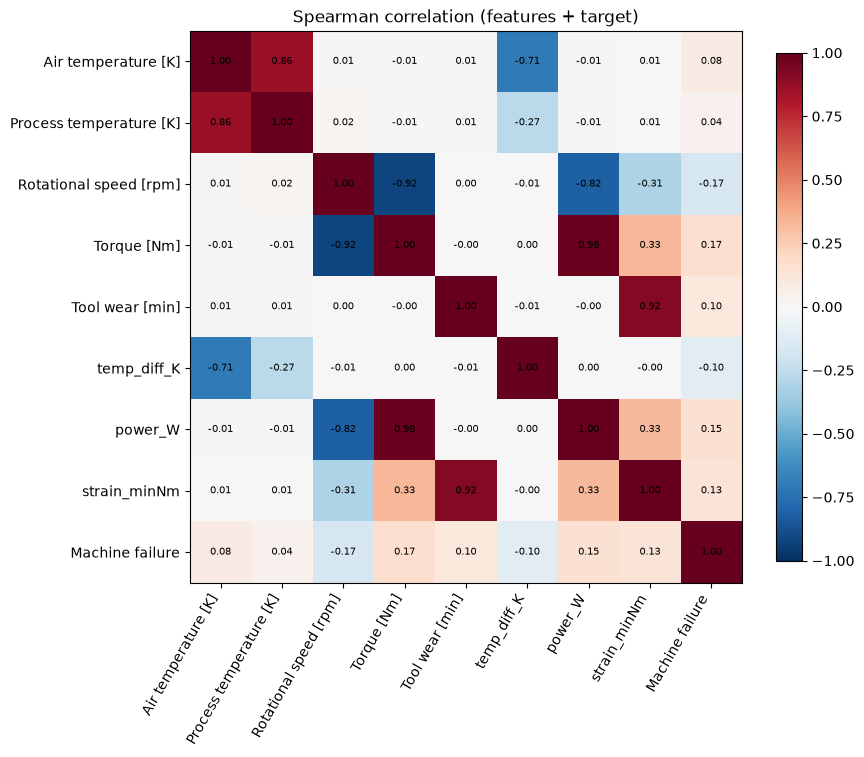

In [14]:
corr_cols = cols + [TARGET]
corr = eda[corr_cols].corr(method="spearman")

fig, ax = plt.subplots(figsize=(9, 8))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=60, ha="right")
ax.set_yticks(range(len(corr)), corr.columns)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f"{corr.iat[i, j]:.2f}", ha="center", va="center", fontsize=7)
fig.colorbar(im, ax=ax, shrink=0.8)
ax.set_title("Spearman correlation (features + target)")
fig.tight_layout()
fig.savefig(FIG_DIR / "01_eda_correlation.png", dpi=120)
plt.show()

Cell F — Leakage proof: a rule with no ML at all:

### Findings (failure mechanisms)

- The documented failure rules are visible in the data: HDF (temp diff < 8.6 K AND speed < 1380 rpm),
  PWF (power < 3500 W or > 9000 W), OSF (tool wear x torque above a type-specific limit, lowest for L),
  TWF (tool wear ~200-240 min, partly random).
- Failures sit at thresholds, at both extremes and in interactions — not on a straight line.
  Therefore all Spearman correlations with the target are weak (|rho| <= 0.17) although the rules are clear.
  **Low correlation does not mean a useless feature.** Tree-based models and physical features are expected to help.
- Strong multicollinearity: power ~ torque (0.98), strain ~ tool wear (0.92), torque ~ speed (-0.92).
  Relevant for linear models (regularisation), not for trees.
- RNF shows no sensor pattern (random by design).

In [15]:
# "Model": predict failure if ANY failure-mode flag is set.
rule_pred = eda[MODES].any(axis=1)
y = eda[TARGET].eq(1)

tp = int((rule_pred & y).sum())
fp = int((rule_pred & ~y).sum())
fn = int((~rule_pred & y).sum())
tn = int((~rule_pred & ~y).sum())

pd.DataFrame(
    {
        "TP": [tp],
        "FP": [fp],
        "FN": [fn],
        "TN": [tn],
        "recall": [round(tp / (tp + fn), 3)],
        "precision": [round(tp / (tp + fp), 3)],
    },
    index=["rule: any(TWF..RNF)"],
)

,TP,FP,FN,TN,recall,precision
rule: any(TWF..RNF),330,18,9,9643,0.973,0.948


### Leakage finding

The columns `TWF`, `HDF`, `PWF`, `OSF`, `RNF` are **not sensor readings**. They are labels
that describe *which* failure happened, and they are only known **after** the failure.
A simple rule "failure if any mode flag is set" — no machine learning at all — already reaches
the recall and precision shown above. Any model that sees these columns will look almost
perfect and be useless in production.

**Decision:** the five mode columns are excluded from all feature sets. They are only used
as the target for the multi-class task (question 2). An automated pytest
(`tests/test_leakage.py`, planned 31.10) will fail if any of them appears in the features.

**Known limitation:** `RNF` is random by design and cannot be predicted from sensors.